# SIYAQ

In [153]:
import pandas as pd
import matplotlib.pyplot as plt
import csv
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

# Part 1 - Dataset Preparation

### 1.1 Download and load the dataset

The UCI dataset has three files: Amazon, IMDb and Yelp. Each row contains a review sentence and its sentiment label (0 = negative, 1 = positive).

In [154]:
files_data = {"Amazon": "amazon_cells_labelled.txt","IMDb": "imdb_labelled.txt","Yelp": "yelp_labelled.txt"}
data = []
for source, filename in files_data.items():
    part = pd.read_csv(
        filename,
        sep="\t",
        header=None,
        names=["text", "label"],
        quoting=csv.QUOTE_NONE
        )
    part["source"] = source
    data.append(part)
df = pd.concat(data, ignore_index=True)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3000, 3)


,text,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,Amazon
4,The mic is great.,1,Amazon


### 1.2 Explore the dataset

In [155]:
print("Number of reviews:", len(df))
print("Missing values:")
print(df.isnull().sum())
print('-------------------')
print("Reviews by source:")
print(df["source"].value_counts())
print('-------------------')
print("Sentiment labels (0 = negative, 1 = positive):")
print(df["label"].value_counts().sort_index())
print('-------------------')
print("Sentiment by source:")
print(pd.crosstab(df["source"], df["label"]))

Number of reviews: 3000
Missing values:
text      0
label     0
source    0
dtype: int64
-------------------
Reviews by source:
source
Amazon    1000
IMDb      1000
Yelp      1000
Name: count, dtype: int64
-------------------
Sentiment labels (0 = negative, 1 = positive):
label
0    1500
1    1500
Name: count, dtype: int64
-------------------
Sentiment by source:
label     0    1
source          
Amazon  500  500
IMDb    500  500
Yelp    500  500


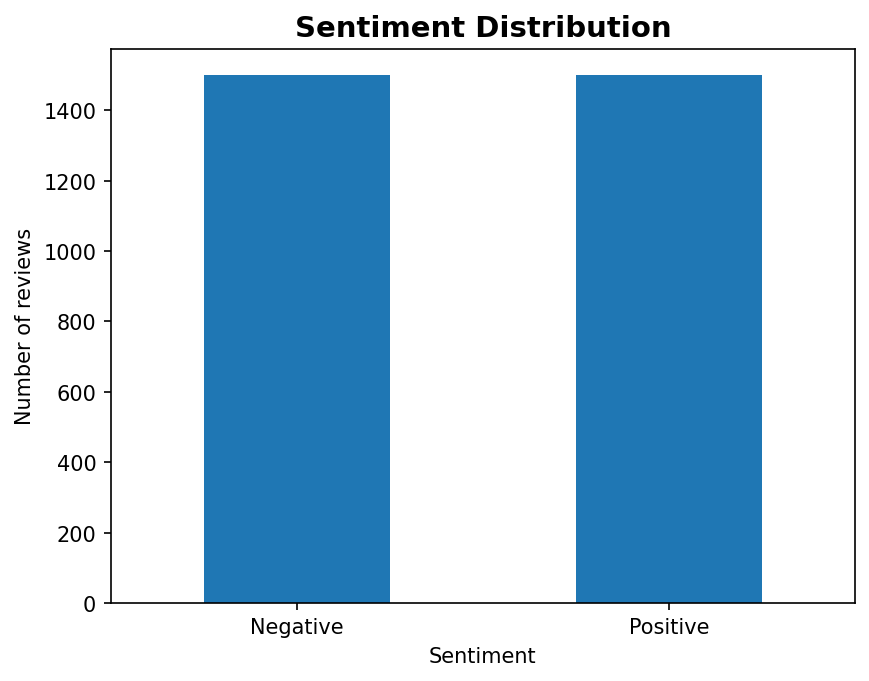

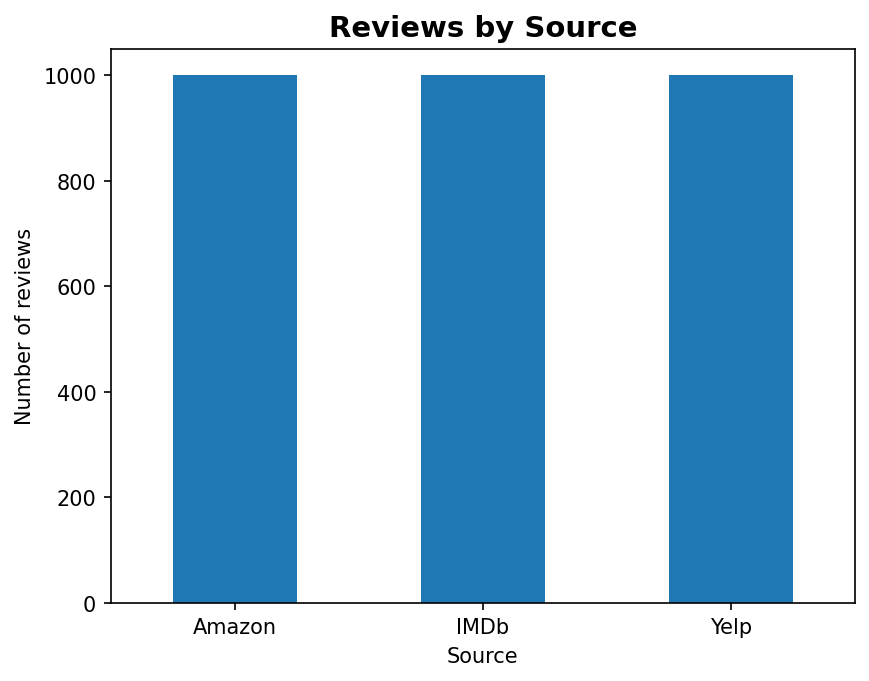

In [156]:
df["label"].value_counts().sort_index().rename(index={0: "Negative", 1: "Positive"}).plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

df["source"].value_counts().plot(kind="bar")
plt.title("Reviews by Source")
plt.xlabel("Source")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

### 1.3 Preprocess the data

Remove rows with missing or empty text and trim extra spaces. Negation words, contrast markers and punctuation are kept.

In [157]:
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].str.strip()
df = df[df["text"] != ""].copy()
df["label"] = df["label"].astype(int)

df = df.reset_index(drop=True)
df.insert(0, "record_id", range(1, len(df) + 1))

print("Rows after preprocessing:", len(df))

Rows after preprocessing: 3000


### 1.4 Check exact duplicates

For duplicate checking, we lowercased the sentence and normalized extra spaces. The original review text is kept unchanged.

In [158]:
df["duplicate_key"] = (df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip())
exact_duplicates = df[df.duplicated("duplicate_key", keep=False)].sort_values("duplicate_key")

print("Rows in exact-duplicate groups:", len(exact_duplicates))
display(exact_duplicates[["record_id", "source", "text", "label"]].head(20))

conflicts = exact_duplicates.groupby("duplicate_key")["label"].nunique()
conflicts = conflicts[conflicts > 1]
if len(conflicts) > 0:
    display(exact_duplicates[exact_duplicates["duplicate_key"].isin(conflicts.index)])
    raise ValueError("Review the duplicate sentences with conflicting labels first")

df = df.drop_duplicates("duplicate_key", keep="first").copy()
print("Rows after removing exact duplicates:", len(df))

Rows in exact-duplicate groups: 40


,record_id,source,text,label
1125,1126,IMDb,10/10,1
1788,1789,IMDb,10/10,1
1090,1091,IMDb,Definitely worth checking out.,1
1363,1364,IMDb,Definitely worth checking out.,1
748,749,Amazon,Does not fit.,0
446,447,Amazon,Does not fit.,0
543,544,Amazon,Don't buy this product.,0
180,181,Amazon,Don't buy this product.,0
892,893,Amazon,Excellent product for the price.,1
402,403,Amazon,Excellent product for the price.,1


Rows after removing exact duplicates: 2979


### 1.5 Check near duplicates

In [159]:
vectorizer = TfidfVectorizer(analyzer="char_wb",ngram_range=(3, 5))
text_vectors = vectorizer.fit_transform(df["text"])
similarities = cosine_similarity(text_vectors, dense_output=False).tocoo()

rows_to_remove = set()

for i, j, score in zip(similarities.row, similarities.col, similarities.data):
    if i < j and score >= 0.90:
        if df.iloc[i]["label"] == df.iloc[j]["label"]:
            rows_to_remove.add(df.index[j])
            print("Review 1:", df.iloc[i]["text"])
            print("Review 2:", df.iloc[j]["text"])
            print("Similarity:", round(score, 3))
            print("---------------")

df_clean = df.drop(index=rows_to_remove).copy()

print("Near duplicates removed:", len(rows_to_remove))
print("Final dataset size:", len(df_clean))

Review 1: VERY DISAPPOINTED.
Review 2: disappointed.
Similarity: 0.944
---------------
Review 1: Great phone!.
Review 2: This is a great phone!.
Similarity: 0.945
---------------
Review 1: We are sending it back.
Review 2: Sending it back.
Similarity: 0.929
---------------
Review 1: Great Phone.
Review 2: It was a great phone.
Similarity: 0.924
---------------
Review 1: Very disappointing.
Review 2: disappointing.
Similarity: 0.949
---------------
Review 1: Waste of money.
Review 2: It was a waste of my money.
Similarity: 0.933
---------------
Review 1: Very easy to use.
Review 2: Easy to use.
Similarity: 0.919
---------------
Review 1: Avoid at all costs.
Review 2: Avoid this film at all costs.
Similarity: 0.923
---------------
Review 1: Avoid at all costs.
Review 2: Avoid at any and all costs.
Similarity: 0.942
---------------
Review 1: It is not good.
Review 2: It was not good.
Similarity: 0.909
---------------
Review 1: Won't go back.
Review 2: I won't be back.
Similarity: 0.915
--

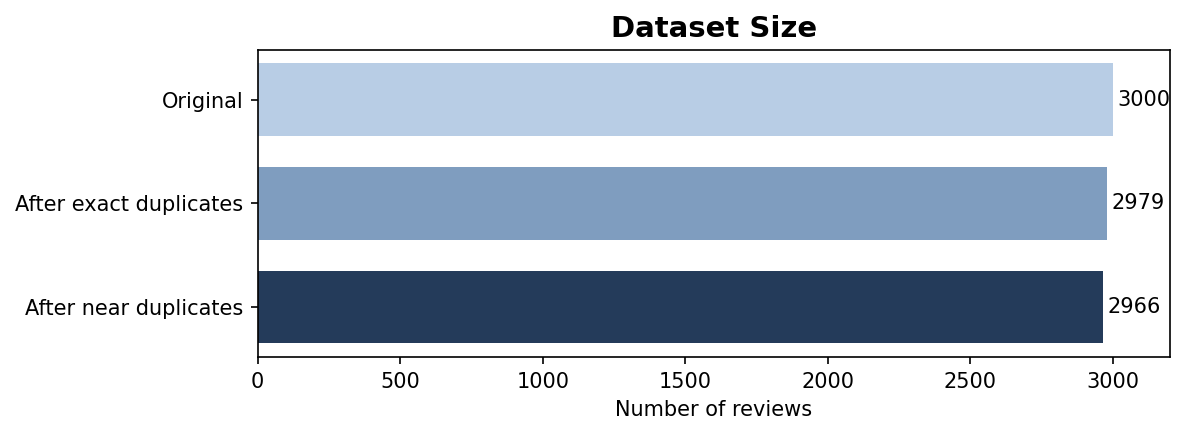

In [160]:
import matplotlib.pyplot as plt
stages = ["Original", "After exact duplicates", "After near duplicates"]
counts = [3000, 2979, 2966]
plt.figure(figsize=(8, 3))

bars = plt.barh(stages, counts, height=0.7,color=["#B8CDE5", "#7F9DBF", "#243B5A"])
for bar in bars:
    plt.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2,
             f"{int(bar.get_width())}", va="center")

plt.title("Dataset Size")
plt.xlabel("Number of reviews")
plt.xlim(0, 3200)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 1.6 Split the dataset

Training, development and test sets. Stratification keeps the positive/negative proportions similar across the three sets.

In [161]:
train, temp = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["label"]
)

development, test = train_test_split(
    temp,
    test_size=0.50,
    random_state=42,
    stratify=temp["label"]
)

print("Training:", len(train))
print("Development:", len(development))
print("Test:", len(test))

Training: 2076
Development: 445
Test: 445


### 1.7 Check and save the partitions

In [162]:
for name, part in [("Training", train),("Development", development),("Test", test)]:
    print("\n" + name)
    print(part["label"].value_counts().sort_index().rename(
        index={0: "Negative", 1: "Positive"}))

assert len(train) + len(development) + len(test) == len(df_clean)
columns_to_save = ["text", "label", "source"]
train[columns_to_save].to_csv("train.csv", index=False)
development[columns_to_save].to_csv("development.csv", index=False)
test[columns_to_save].to_csv("test.csv", index=False)

print("The three partition files have been saved")


Training
label
Negative    1037
Positive    1039
Name: count, dtype: int64

Development
label
Negative    222
Positive    223
Name: count, dtype: int64

Test
label
Negative    223
Positive    222
Name: count, dtype: int64
The three partition files have been saved


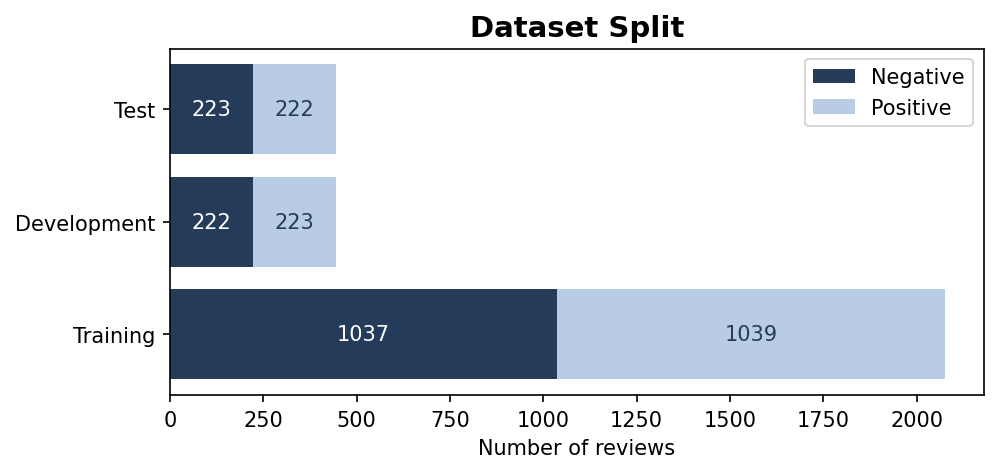

In [163]:
splits = ["Training", "Development", "Test"]
negative = [1037, 222, 223]
positive = [1039, 223, 222]
y = range(3)
plt.figure(figsize=(7, 3))
bars1 = plt.barh(y, negative, color="#243B5A", label="Negative")
bars2 = plt.barh(y, positive, left=negative, color="#B8CDE5", label="Positive")
for bar in bars1:
    plt.text(bar.get_width()/2, bar.get_y() + bar.get_height()/2,
             int(bar.get_width()), ha="center", va="center", color="white")
for bar in bars2:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2,
             int(bar.get_width()), ha="center", va="center", color="#243B5A")

plt.yticks(y, splits)
plt.title("Dataset Split")
plt.xlabel("Number of reviews")
plt.legend()
plt.show()

# Part 2 - TF-IDF + Logistic Regression and Negation Analysis

## 2. Method 1: TF-IDF with Logistic Regression

In this section, we implement a traditional sentiment classification model using TF-IDF features and Logistic Regression.

In [164]:
train_df = pd.read_csv("train.csv")
dev_df = pd.read_csv("development.csv")
test_df = pd.read_csv("test.csv")

print("Training:", train_df.shape)
print("Development:", dev_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Training: (2076, 3)
Development: (445, 3)
Test: (445, 3)


,text,label,source
0,Phone falls out easily.,0,Amazon
1,"It's too bad that everyone else involved didn't share Crowe's level of dedication to quality, for if they did, we'd have a far better film on our hands than this sub-par mess.",0,IMDb
2,The vanilla ice cream was creamy and smooth while the profiterole (choux) pastry was fresh enough.,1,Yelp
3,"When I placed my treo into the case, not only was it NOT snug, but there was A LOT of extra room on the sides.",0,Amazon
4,We definately enjoyed ourselves.,1,Yelp


### 2.1 TF-IDF Features

We use TF-IDF to convert the reviews into numerical features so they can be used to train our model.

In [165]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)

X_train = tfidf.fit_transform(train_df["text"])
X_dev = tfidf.transform(dev_df["text"])

y_train = train_df["label"]
y_dev = dev_df["label"]

print("Training features:", X_train.shape)
print("Development features:", X_dev.shape)

Training features: (2076, 5000)
Development features: (445, 5000)


### 2.2 Logistic Regression

We train a Logistic Regression model using the TF-IDF features and check its performance on the development set.

In [166]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

dev_predictions = lr_model.predict(X_dev)

dev_accuracy = accuracy_score(y_dev, dev_predictions)
dev_f1 = f1_score(y_dev, dev_predictions, average="macro")

print("Development Accuracy:", round(dev_accuracy, 4))
print("Development Macro F1:", round(dev_f1, 4))

Development Accuracy: 0.8315
Development Macro F1: 0.8315


### 2.3 Model Tuning

We try different C values for Logistic Regression and select the one with the highest Macro F1 score on the development set.

In [167]:
results = []

for c in [0.1, 1, 10]:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    predictions = model.predict(X_dev)

    acc = accuracy_score(y_dev, predictions)
    f1 = f1_score(y_dev, predictions, average="macro")

    results.append([c, acc, f1])

results_df = pd.DataFrame(
    results,
    columns=["C", "Accuracy", "Macro F1"]
)

display(results_df)

best_c = results_df.loc[results_df["Macro F1"].idxmax(), "C"]

print("Best C:", best_c)

,C,Accuracy,Macro F1
0,0.1,0.797753,0.797703
1,1.0,0.831461,0.831457
2,10.0,0.847191,0.847184


Best C: 10.0


### 2.4 Final Model Evaluation

We use the best C value selected from the development set and evaluate the model on the test set.

In [168]:
final_model = LogisticRegression(
    C=best_c,
    max_iter=1000,
    random_state=42
)

final_model.fit(X_train, y_train)

X_test = tfidf.transform(test_df["text"])
y_test = test_df["label"]

test_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions, average="macro")

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_f1, 4))

Test Accuracy: 0.8157
Test Macro F1: 0.8156


### 2.5 Negation Subset Identification

We identify reviews containing common negation words to study how negation affects sentiment classification.

In [169]:
import re

negation_words = [
    "not", "no", "never", "isn't", "wasn't",
    "doesn't", "didn't", "don't", "can't",
    "won't", "couldn't", "wouldn't"
]

pattern = r"\b(?:" + "|".join(re.escape(word) for word in negation_words) + r")\b"

negation_candidates = test_df[
    test_df["text"].str.contains(pattern, case=False, regex=True, na=False)
].copy()

print("Negation candidates:", len(negation_candidates))

display(negation_candidates[["text", "label"]])

Negation candidates: 88


,text,label
12,"The ripped banana was not only ripped, but petrified and tasteless.",0
14,"Will never, ever go back.",0
17,I can assure you that you won't be disappointed.,1
29,"I won't say any more - I don't like spoilers, so I don't want to be one, but I believe this film is worth your time.",1
31,"Great Subway, in fact it's so good when you come here every other Subway will not meet your expectations.",1
...,...,...
428,I can't wait to go back.,1
431,"By this point, my friends and I had basically figured out this place was a joke and didn't mind making it publicly and loudly known.",0
436,"This item is great, installed it, let it charged up overnite and it has been working good every since with no problems",1
437,I'm not really sure how Joey's was voted best hot dog in the Valley by readers of Phoenix Magazine.,0


### 2.6 Manual Verification of Negation

We manually check the candidate reviews to confirm that the negation words are used as actual negation.

In [170]:
for idx, row in negation_candidates.iterrows():
    print(f"Index: {idx}")
    print(f"Review: {row['text']}")
    print(f"Label: {row['label']}")
    print("-" * 50)

Index: 12
Review: The ripped banana was not only ripped, but petrified and tasteless.
Label: 0
--------------------------------------------------
Index: 14
Review: Will never, ever go back.
Label: 0
--------------------------------------------------
Index: 17
Review: I can assure you that you won't be disappointed.
Label: 1
--------------------------------------------------
Index: 29
Review: I won't say any more - I don't like spoilers, so I don't want to be one, but I believe this film is worth your time.
Label: 1
--------------------------------------------------
Index: 31
Review: Great Subway, in fact it's so good when you come here every other Subway will not meet your expectations.
Label: 1
--------------------------------------------------
Index: 32
Review: I had absolutely no problem with this headset linking to my 8530 Blackberry Curve!
Label: 1
--------------------------------------------------
Index: 33
Review: I'm probably one of the few people to ever go to Ians and not lik

### 2.7 Verified Negation Subset

We reviewed the negation candidates and excluded expressions that do not represent the intended negation challenge. We kept the original sentiment labels.

In [171]:
excluded_indices = [12, 66]

verified_negation = negation_candidates.drop(
    index=excluded_indices
).copy()

print("Candidates:", len(negation_candidates))
print("Excluded:", len(excluded_indices))
print("Verified negation:", len(verified_negation))

print("\nLabel distribution:")
print(verified_negation["label"].value_counts())

Candidates: 88
Excluded: 2
Verified negation: 86

Label distribution:
label
0    59
1    27
Name: count, dtype: int64


### 2.8 Negation Evaluation

We evaluate the TF-IDF and Logistic Regression model on the verified negation subset to see how well it handles negation.

In [172]:
X_negation = tfidf.transform(verified_negation["text"])
y_negation = verified_negation["label"]

negation_predictions = final_model.predict(X_negation)

neg_accuracy = accuracy_score(y_negation, negation_predictions)
neg_f1 = f1_score(y_negation, negation_predictions, average="macro")

print("Negation Accuracy:", round(neg_accuracy, 4))
print("Negation Macro F1:", round(neg_f1, 4))

Negation Accuracy: 0.7326
Negation Macro F1: 0.6434


### 2.9 Negation Error Analysis

We examine the misclassified reviews to understand where the model struggles with negation.

In [173]:
negation_results = verified_negation.copy()
negation_results["predicted"] = negation_predictions

negation_errors = negation_results[
    negation_results["label"] != negation_results["predicted"]
]

print("Total errors:", len(negation_errors))

display(negation_errors[["text", "label", "predicted"]])

Total errors: 23


,text,label,predicted
29,"I won't say any more - I don't like spoilers, so I don't want to be one, but I believe this film is worth your time.",1,0
32,I had absolutely no problem with this headset linking to my 8530 Blackberry Curve!,1,0
34,"Love this place, hits the spot when I want something healthy but not lacking in quantity or flavor.",1,0
58,They brought a fresh batch of fries and I was thinking yay something warm but no!,0,1
74,"Director Neil LaBute uses brutal violence to seperate dreams from reality, and along with the touching drama, and hilarious comedy, you can never tell what is going to happen next.",1,0
138,I was looking for this headset for a long time and now that I've got it I couldn't be happier.,1,0
140,The food wasn't good.,0,1
179,""" In fact, it's hard to remember that the part of Ray Charles is being acted, and not played by the man himself.",1,0
192,good protection and does not make phone too bulky.,1,0
224,We made the drive all the way from North Scottsdale... and I was not one bit disappointed!,1,0


### 2.10 Error Analysis Examples

We selected three misclassified reviews to examine how negation may affect sentiment predictions.

In [174]:
selected_errors = negation_errors.loc[[140, 231, 428]]

for idx, row in selected_errors.iterrows():
    print("Review:", row["text"])
    print("Actual label:", "Positive" if row["label"] == 1 else "Negative")
    print("Predicted label:", "Positive" if row["predicted"] == 1 else "Negative")
    print("-" * 50)

Review: The food wasn't good.
Actual label: Negative
Predicted label: Positive
--------------------------------------------------
Review: The soundtrack wasn't terrible, either.
Actual label: Positive
Predicted label: Negative
--------------------------------------------------
Review: I can't wait to go back.
Actual label: Positive
Predicted label: Negative
--------------------------------------------------


### 2.11 Results Summary

We compare the model's overall test performance with its performance on reviews containing negation.

In [175]:
summary = pd.DataFrame({
    "Dataset": ["Overall Test", "Negation Subset"],
    "Samples": [len(test_df), len(verified_negation)],
    "Accuracy": [test_accuracy, neg_accuracy],
    "Macro F1": [test_f1, neg_f1]
})

display(summary.round(4))

,Dataset,Samples,Accuracy,Macro F1
0,Overall Test,445,0.8157,0.8156
1,Negation Subset,86,0.7326,0.6434


# Part 3 - all-MiniLM-L6-v2 + Logistic Regression and Contrastive Language Analysis

## 3. Method 2: all-MiniLM-L6-v2 + Logistic Regression

### 3.1 Install and import libraries

In [176]:
!pip install -q sentence-transformers

from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

### 3.2 Load the pretrained model

In [177]:
model = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

### 3.3 Generate sentence embeddings

In [178]:
X_train_emb = model.encode(train["text"].tolist(), show_progress_bar=True)
X_dev_emb = model.encode(development["text"].tolist(), show_progress_bar=True)
X_test_emb = model.encode(test["text"].tolist(), show_progress_bar=True)

y_train = train["label"].values
y_dev = development["label"].values
y_test = test["label"].values

print("Embedding shape (train):", X_train_emb.shape)
print("Embedding shape (development):", X_dev_emb.shape)
print("Embedding shape (test):", X_test_emb.shape)

Batches:   0%|          | 0/65 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Embedding shape (train): (2076, 384)
Embedding shape (development): (445, 384)
Embedding shape (test): (445, 384)


### 3.4 Train Logistic Regression

In [179]:
lr_minilm = LogisticRegression(max_iter=1000, random_state=42)
lr_minilm.fit(X_train_emb, y_train)

LogisticRegression(max_iter=1000, random_state=42)

### 3.5 Evaluate development performance

In [180]:
dev_pred = lr_minilm.predict(X_dev_emb)

print("Development Accuracy:", round(accuracy_score(y_dev, dev_pred), 4))
print("Development Macro F1:", round(f1_score(y_dev, dev_pred, average="macro"), 4))

Development Accuracy: 0.8899
Development Macro F1: 0.8897


### 3.6 Test different C values

In [181]:
c_values = [0.01, 0.1, 1, 10, 100]
tuning_results = []

for c in c_values:
    clf = LogisticRegression(C=c, max_iter=1000, random_state=42)
    clf.fit(X_train_emb, y_train)
    pred = clf.predict(X_dev_emb)
    tuning_results.append({
        "C": c,
        "dev_accuracy": round(accuracy_score(y_dev, pred), 4),
        "dev_macro_f1": round(f1_score(y_dev, pred, average="macro"), 4)
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

# Choose the C value with the highest development Macro F1
best_c = tuning_df.loc[tuning_df["dev_macro_f1"].idxmax(), "C"]
print("Best C:", best_c)

,C,dev_accuracy,dev_macro_f1
0,0.01,0.8899,0.8898
1,0.10,0.8966,0.8965
2,1.00,0.8899,0.8897
3,10.00,0.8921,0.8921
4,100.00,0.8742,0.8741


Best C: 0.1


### 3.7 Train final model

In [182]:
final_lr_minilm = LogisticRegression(C=best_c, max_iter=1000, random_state=42)
final_lr_minilm.fit(X_train_emb, y_train)

LogisticRegression(C=np.float64(0.1), max_iter=1000, random_state=42)

### 3.8 Evaluate final test results

In [183]:
test_pred = final_lr_minilm.predict(X_test_emb)

minilm_test_accuracy = accuracy_score(y_test, test_pred)
minilm_test_macro_f1 = f1_score(y_test, test_pred, average="macro")

print("Test Accuracy:", round(minilm_test_accuracy, 4))
print("Test Macro F1:", round(minilm_test_macro_f1, 4))
print()
print(classification_report(y_test, test_pred, target_names=["Negative", "Positive"], digits=4))

Test Accuracy: 0.8674
Test Macro F1: 0.8673

              precision    recall  f1-score   support

    Negative     0.8475    0.8969    0.8715       223
    Positive     0.8900    0.8378    0.8631       222

    accuracy                         0.8674       445
   macro avg     0.8687    0.8673    0.8673       445
weighted avg     0.8687    0.8674    0.8673       445



### 3.9 Attach predictions to test examples

In [184]:
print("Test columns:", list(test.columns))

minilm_results = test[["record_id", "source", "text", "label"]].copy()
minilm_results["prediction"] = test_pred
minilm_results["correct"] = minilm_results["prediction"] == minilm_results["label"]

minilm_results.to_csv("minilm_test_predictions.csv", index=False)
display(minilm_results.head())

Test columns: ['record_id', 'text', 'label', 'source', 'duplicate_key']


,record_id,source,text,label,prediction,correct
2399,2400,Yelp,Cooked to perfection and the service was impeccable.,1,1,True
1672,1673,IMDb,"It felt like a very gripping, intelligent stage play (but without the overly theatrical feeling one actually gets from watching people on a stage) which plays on everyone's terror of a white lie escalating to monstrous consequences.",1,1,True
1472,1473,IMDb,"The plot, such as it is, is so derivative and predictable that the ending is like a mercy killing.",0,0,True
954,955,Amazon,This is the phone to get for 2005.... I just bought my S710a and all I can say is WOW!,1,1,True
918,919,Amazon,Works for me.,1,0,False


## Contrastive Subset (Primary Challenge)

### 3.10 Find contrastive candidate sentences

In [185]:
contrast_markers = ["but", "however", "although", "though", "yet", "whereas", "nevertheless"]
contrast_pattern = r"\b(" + "|".join(contrast_markers) + r")\b"

minilm_results["contrast_marker"] = minilm_results["text"].str.lower().str.extract(contrast_pattern)[0]
minilm_results["is_candidate"] = minilm_results["contrast_marker"].notna()

candidates = minilm_results[minilm_results["is_candidate"]]
print("Contrastive candidates in test set:", len(candidates))
print(candidates["contrast_marker"].value_counts())

pd.set_option("display.max_colwidth", 250)
display(candidates[["record_id", "contrast_marker", "text", "label"]])

Contrastive candidates in test set: 38
contrast_marker
but         32
however      4
although     1
though       1
Name: count, dtype: int64


,record_id,contrast_marker,text,label
1672,1673,but,"It felt like a very gripping, intelligent stage play (but without the overly theatrical feeling one actually gets from watching people on a stage) which plays on everyone's terror of a white lie escalating to monstrous consequences.",1
2059,2060,but,"The ripped banana was not only ripped, but petrified and tasteless.",0
1449,1450,but,"I won't say any more - I don't like spoilers, so I don't want to be one, but I believe this film is worth your time.",1
2184,2185,but,"Love this place, hits the spot when I want something healthy but not lacking in quantity or flavor.",1
1534,1535,but,but the movie makes a lot of serious mistakes.,0
2918,2919,but,They brought a fresh batch of fries and I was thinking yay something warm but no!,0
1523,1524,but,20th Century Fox's ROAD HOUSE 1948) is not only quite a silly noir but is an implausible unmitigated bore of a movie.,0
2074,2075,but,"I guess I should have known that this place would suck, because it is inside of the Excalibur, but I didn't use my common sense.",0
2955,2956,but,But then they came back cold.,0
2119,2120,although,"Although I very much liked the look and sound of this place, the actual experience was a bit disappointing.",0


### 3.11 Remove non-contrastive false positives

In [186]:
START = "Marker starts the sentence without an internal contrast"
ADDITIVE = "Additive construction rather than contrast (not only ... but)"
IDIOM = "Non-contrastive or idiomatic usage"
NO_OPINION = "One side does not express an opinion or conflicting evaluation"

exclusion_reasons = {
    1535: START, 2956: START, 2925: START, 190: START, 327: START,
    835: START, 2764: START, 1231: START, 1238: START, 1260: START,
    2060: ADDITIVE, 1524: ADDITIVE,
    711: IDIOM, 1846: IDIOM,
    2075: NO_OPINION, 2419: NO_OPINION, 1450: NO_OPINION,
    2624: NO_OPINION, 2453: NO_OPINION, 2577: NO_OPINION,
}
false_positive_ids = list(exclusion_reasons.keys())

minilm_results["is_contrastive"] = minilm_results["is_candidate"] & ~minilm_results["record_id"].isin(false_positive_ids)
contrastive = minilm_results[minilm_results["is_contrastive"]]

excluded_table = candidates[candidates["record_id"].isin(false_positive_ids)][["record_id", "contrast_marker", "text"]].copy()
excluded_table["exclusion_reason"] = excluded_table["record_id"].map(exclusion_reasons)
excluded_table["text"] = excluded_table["text"].str[:80]
excluded_table = excluded_table.rename(columns={"record_id": "Record ID", "contrast_marker": "Marker",
                                                "exclusion_reason": "Exclusion Reason", "text": "Text (shortened)"})
display(excluded_table[["Record ID", "Marker", "Exclusion Reason", "Text (shortened)"]].sort_values("Exclusion Reason"))

,Record ID,Marker,Exclusion Reason,Text (shortened)
2059,2060,but,Additive construction rather than contrast (not only ... but),"The ripped banana was not only ripped, but petrified and tasteless."
1523,1524,but,Additive construction rather than contrast (not only ... but),20th Century Fox's ROAD HOUSE 1948) is not only quite a silly noir but is an imp
1237,1238,but,Marker starts the sentence without an internal contrast,But what really made it unwatchable was the direction.
1230,1231,however,Marker starts the sentence without an internal contrast,"However, I recently watched the whole thing again on DVD, and I was completely s"
2763,2764,but,Marker starts the sentence without an internal contrast,But the service was beyond bad.
834,835,however,Marker starts the sentence without an internal contrast,"However, the ear pads come off easily and after only one week I lost one."
189,190,but,Marker starts the sentence without an internal contrast,"But when I check voice mail at night, the keypad backlight turns off a few secon"
326,327,however,Marker starts the sentence without an internal contrast,"However-the riingtones are not the best, and neither are the games."
2955,2956,but,Marker starts the sentence without an internal contrast,But then they came back cold.
1534,1535,but,Marker starts the sentence without an internal contrast,but the movie makes a lot of serious mistakes.


### 3.12 Show contrastive subset counts

In [187]:
print("Candidates found:", len(candidates))
print("Removed after manual check:", len(false_positive_ids))
print("Verified contrastive examples:", len(contrastive))
print()
print("Label distribution (0 = negative, 1 = positive):")
print(contrastive["label"].value_counts().sort_index())

Candidates found: 38
Removed after manual check: 20
Verified contrastive examples: 18

Label distribution (0 = negative, 1 = positive):
label
0     7
1    11
Name: count, dtype: int64


### 3.13 Analyze contrastive performance

In [188]:
def evaluate_subset(name, part):
    return {
        "subset": name,
        "n": len(part),
        "accuracy": round(accuracy_score(part["label"], part["prediction"]), 4),
        "macro_f1": round(f1_score(part["label"], part["prediction"], average="macro"), 4)
    }

non_contrastive = minilm_results[~minilm_results["is_contrastive"]]

comparison = pd.DataFrame([
    evaluate_subset("Overall test set", minilm_results),
    evaluate_subset("Contrastive subset", contrastive),
    evaluate_subset("Non-contrastive", non_contrastive)
])
display(comparison)

,subset,n,accuracy,macro_f1
0,Overall test set,445,0.8674,0.8673
1,Contrastive subset,18,0.7778,0.7662
2,Non-contrastive,427,0.8712,0.8710


### 3.14 Plot contrastive vs overall

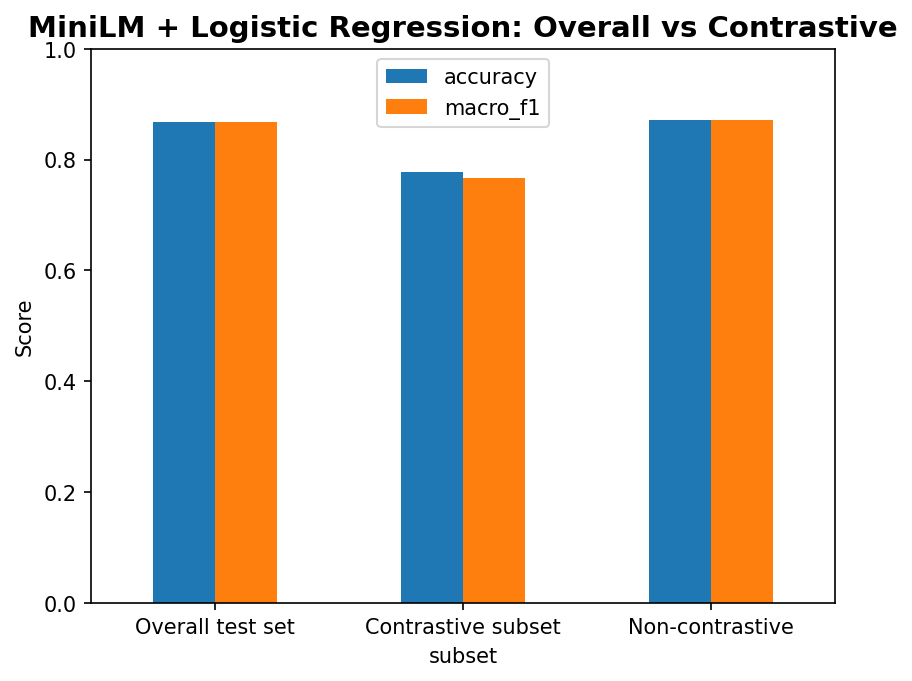

In [189]:
comparison.set_index("subset")[["accuracy", "macro_f1"]].plot(kind="bar")
plt.title("MiniLM + Logistic Regression: Overall vs Contrastive")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

### 3.15 Review misclassified contrastive examples

In [190]:
contrastive_errors = contrastive[~contrastive["correct"]]

print("Misclassified contrastive examples:", len(contrastive_errors), "out of", len(contrastive))
display(contrastive_errors[["record_id", "source", "contrast_marker", "text", "label", "prediction"]])

Misclassified contrastive examples: 4 out of 18


,record_id,source,contrast_marker,text,label,prediction
2119,2120,Yelp,although,"Although I very much liked the look and sound of this place, the actual experience was a bit disappointing.",0,1
1072,1073,IMDb,but,"It crackles with an unpredictable, youthful energy - but honestly, i found it hard to follow and concentrate on it meanders so badly.",0,1
624,625,Amazon,but,All the other cases I've tried normally fall apart after a few months but this one seems to be in for the long haul.,1,0
852,853,Amazon,but,I have read other's reviews here but I haven't had any problem with it.,1,0


### 3.16 Summarize primary challenge

In [191]:
overall_acc = comparison.loc[0, "accuracy"]
contrast_acc = comparison.loc[1, "accuracy"]
overall_err = 1 - overall_acc
contrast_err = 1 - contrast_acc

print("Overall accuracy:     ", overall_acc)
print("Contrastive accuracy: ", contrast_acc)
print("Accuracy drop:        ", round(overall_acc - contrast_acc, 4))
print()
print("Overall error rate:    ", round(overall_err, 4))
print("Contrastive error rate:", round(contrast_err, 4))
if overall_err > 0:
    print("Contrastive errors are", round(contrast_err / overall_err, 2), "times the overall error rate")
print()
print("Share of test set that is contrastive:", round(len(contrastive) / len(minilm_results), 4))
print("Share of all test errors that are contrastive:",
      round(len(contrastive_errors) / (~minilm_results["correct"]).sum(), 4))

Overall accuracy:      0.8674
Contrastive accuracy:  0.7778
Accuracy drop:         0.0896

Overall error rate:     0.1326
Contrastive error rate: 0.2222
Contrastive errors are 1.68 times the overall error rate

Share of test set that is contrastive: 0.0404
Share of all test errors that are contrastive: 0.0678


### 3.17 Primary challenge analysis

**Result:** MiniLM + Logistic Regression performs worse on contrastive sentences. Accuracy falls from **0.867** on the full test set to **0.778** on the 18 verified contrastive examples (Macro F1: 0.867 → 0.766). The error rate is about **1.7×** higher (0.22 vs 0.13).

**What the errors show:** In all 4 misclassified examples, the two parts of the sentence carry opposite cues, and the prediction matches the part that does **not** match the gold label:
- "**Although** I very much liked the look and sound of this place, the actual experience was a bit disappointing" (gold Negative, predicted Positive)
- "It crackles with an unpredictable, youthful energy - **but** honestly, i found it hard to follow..." (gold Negative, predicted Positive)
- "...normally fall apart after a few months **but** this one seems to be in for the long haul" (gold Positive, predicted Negative)
- "I have read other's reviews here **but** I haven't had any problem with it" (gold Positive, predicted Negative)

**Likely challenge:** One sentence embedding represents the whole sentence, so strong words like *very much liked*, *youthful energy* or *fall apart* can outweigh the part that carries the reviewer's overall opinion. The model does not reliably capture which side of the contrast matters. One error (853) also contains negation, which links this challenge to the negation analysis.

**Limitation:** The verified subset is small (18 examples: 7 negative, 11 positive), so each error changes accuracy by about 5.6 points. These results describe a pattern; they are not a precise measurement.

# Part 4 - Final Model Comparison

### 4.1 Align both models' test predictions

In [192]:
comparison_df = minilm_results.reset_index(drop=True).copy()

# test_df (TF-IDF) and minilm_results come from the same test split, in the same row order
assert (comparison_df["text"] == test_df["text"]).all()
assert (comparison_df["label"] == test_df["label"]).all()

comparison_df["tfidf_pred"] = final_model.predict(X_test)
comparison_df["minilm_pred"] = comparison_df["prediction"]
comparison_df["is_negation"] = comparison_df.index.isin(verified_negation.index)

print("Test examples:", len(comparison_df))
print("Verified contrastive examples:", comparison_df["is_contrastive"].sum())
print("Verified negation examples:", comparison_df["is_negation"].sum())

Test examples: 445
Verified contrastive examples: 18
Verified negation examples: 86


### 4.2 Compare both models side by side

In [193]:
def scores(part, pred_column):
    acc = accuracy_score(part["label"], part[pred_column])
    f1 = f1_score(part["label"], part[pred_column], average="macro")
    return round(acc, 4), round(f1, 4)

contrastive_part = comparison_df[comparison_df["is_contrastive"]]
negation_part = comparison_df[comparison_df["is_negation"]]

rows = []
for model_name, pred_column in [("TF-IDF + LR", "tfidf_pred"), ("MiniLM + LR", "minilm_pred")]:
    overall_acc, overall_f1 = scores(comparison_df, pred_column)
    con_acc, con_f1 = scores(contrastive_part, pred_column)
    neg_acc, neg_f1 = scores(negation_part, pred_column)
    rows.append({
        "Model": model_name,
        "Overall Accuracy": overall_acc, "Overall Macro F1": overall_f1,
        "Contrastive Accuracy": con_acc, "Contrastive Macro F1": con_f1,
        "Negation Accuracy": neg_acc, "Negation Macro F1": neg_f1
    })

final_comparison = pd.DataFrame(rows)
display(final_comparison)

,Model,Overall Accuracy,Overall Macro F1,Contrastive Accuracy,Contrastive Macro F1,Negation Accuracy,Negation Macro F1
0,TF-IDF + LR,0.8157,0.8156,0.6111,0.6000,0.7326,0.6434
1,MiniLM + LR,0.8674,0.8673,0.7778,0.7662,0.8023,0.7574


### 4.3 Plot the model comparison

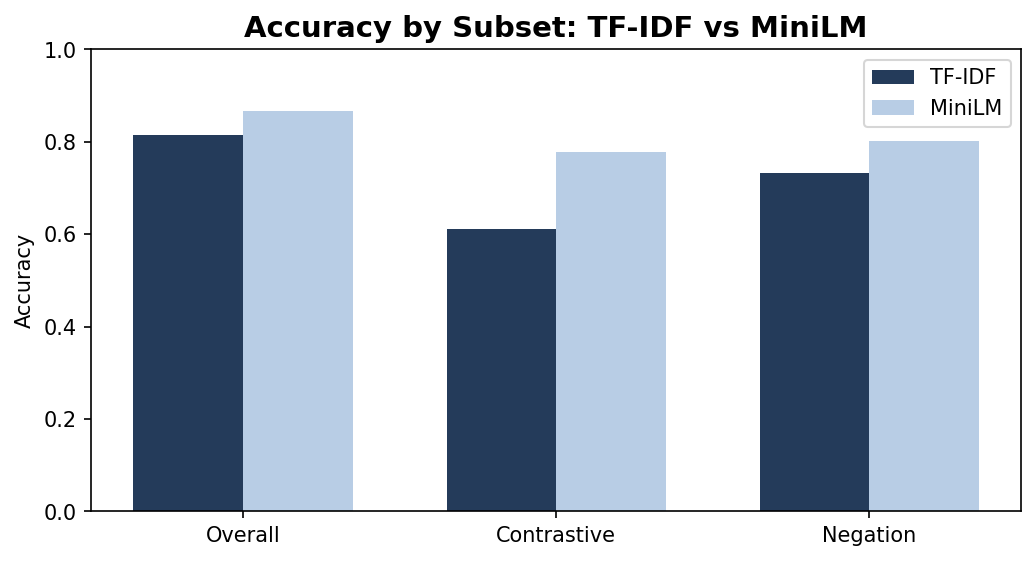

In [194]:
results = final_comparison.set_index("Model")
categories = ["Overall", "Contrastive", "Negation"]
tfidf = [results.loc["TF-IDF + LR", "Overall Accuracy"],results.loc["TF-IDF + LR", "Contrastive Accuracy"],results.loc["TF-IDF + LR", "Negation Accuracy"]]

minilm = [results.loc["MiniLM + LR", "Overall Accuracy"],results.loc["MiniLM + LR", "Contrastive Accuracy"],results.loc["MiniLM + LR", "Negation Accuracy"]]
x = np.arange(3)
plt.figure(figsize=(8, 4))
bars1 = plt.bar(x-0.35/2, tfidf, width=0.35,color="#243B5A", label="TF-IDF")
bars2 = plt.bar(x+0.35/2, minilm, width=0.35,color="#B8CDE5", label="MiniLM")

plt.xticks(x, categories)
plt.title("Accuracy by Subset: TF-IDF vs MiniLM")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.show()

### 4.4 Check the overlap subset

In [195]:
overlap = comparison_df[comparison_df["is_contrastive"] & comparison_df["is_negation"]]

print("Overlap examples (contrastive and negation):", len(overlap))
display(overlap[["record_id", "text", "label", "tfidf_pred", "minilm_pred"]])

Overlap examples (contrastive and negation): 4


,record_id,text,label,tfidf_pred,minilm_pred
34,2185,"Love this place, hits the spot when I want something healthy but not lacking in quantity or flavor.",1,0,1
58,2919,They brought a fresh batch of fries and I was thinking yay something warm but no!,0,1,0
174,1576,"I understand that it's supposed to be a cheap popcorn comedy, but that doesn't mean that it has to completely insult our intelligence, and have writing so incredibly hackneyed that it borders on offensive.",0,0,0
404,655,"The charger arrived within the promised timeframe, but it did not work.",0,0,0


### 4.5 Comparison summary

**Overall:** MiniLM + LR performs better on the full test set (accuracy 0.867 vs 0.820, Macro F1 0.867 vs 0.820).

**Contrastive subset (18 examples):** MiniLM + LR performs better (accuracy 0.778 vs 0.611; 14 vs 11 correct). Both models drop compared with their overall scores, but the drop is larger for TF-IDF (about 21 points vs 9 points).

**Negation subset (86 examples):** MiniLM + LR also performs better (accuracy 0.802 vs 0.733, Macro F1 0.757 vs 0.643). Again, both models score lower than overall.

**Overlap subset:** Only **4** verified examples contain both contrast and negation. With 4 examples, one prediction changes accuracy by 25 points, so no separate performance analysis was done. The examples are listed above for inspection only.

**Interpretation:** On this dataset, the results suggest that the pretrained sentence representation handles contrastive and negated reviews better than TF-IDF, and that both linguistic phenomena remain difficult for both models. However, the contrastive subset is small (18 examples), so the difference between the models should be treated as an indication rather than a firm conclusion.